# Model explainability

I examine how my selected model uses the machine measurements and why it makes particular failure predictions. I load the saved predictor from notebook 07, reproduce its validation scores, and inspect both correct predictions and errors.

I use the same training and validation split. The reserved final test set remains unscored. I keep the fitted model, feature definitions, and demonstration threshold fixed throughout this analysis.

My analysis covers:

1. Permutation importance across the full validation set.
2. SHAP contributions for a random validation sample and selected individual cases.
3. The component scores inside the voting ensemble.
4. The limits of these explanations and the evidence I still need.

## 1. Load the saved experiment

I run this notebook from the project root or its notebook folder. It requires the cleaned CSV, saved split, and model/report files produced by notebook 07. I verify these files before explaining predictions.

This notebook also uses SHAP. If my current Python environment is missing it, I install shap in that environment and restart the kernel. I keep the scikit-learn version used to save the model.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.metrics import average_precision_score
from threadpoolctl import threadpool_limits

try:
    import shap
except ImportError as exc:
    raise ImportError(
        "SHAP is required. Install it in this notebook's Python environment "
        "with %pip install shap, restart the kernel, and rerun the notebook."
    ) from exc

SEED = 42
PERMUTATION_REPEATS = 15
SHAP_BACKGROUND_ROWS = 64
SHAP_GLOBAL_ROWS = 128
SHAP_CHUNK_SIZE = 16

plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 10})

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (
            (candidate / "data/cleaned/ai4i2020_cleaned.csv").is_file()
            and (candidate / "models/ensemble_comparison/model_metadata.json").is_file()
        ):
            return candidate
    raise FileNotFoundError(
        "Open this notebook in the AI4I project root or its notebook folder. "
        "Run notebook 07 first to create the ensemble_comparison artifacts."
    )

PROJECT_ROOT = find_project_root()
INPUTS = {
    "data": PROJECT_ROOT / "data/cleaned/ai4i2020_cleaned.csv",
    "split": PROJECT_ROOT / "reports/smote/split_manifest.csv",
    "model": PROJECT_ROOT / "models/ensemble_comparison/selected_predictor.joblib",
    "metadata": PROJECT_ROOT / "models/ensemble_comparison/model_metadata.json",
    "schema": PROJECT_ROOT / "models/ensemble_comparison/input_schema.json",
    "saved_predictions": PROJECT_ROOT / "reports/ensemble_comparison/selected_validation_predictions.csv",
}
missing = [str(path.relative_to(PROJECT_ROOT)) for path in INPUTS.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Required files are missing:\n" + "\n".join(missing))

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

input_checksums = {name: sha256(path) for name, path in INPUTS.items()}
metadata = json.loads(INPUTS["metadata"].read_text(encoding="utf-8"))
schema = json.loads(INPUTS["schema"].read_text(encoding="utf-8"))
if metadata["versions"]["scikit_learn"] != sklearn.__version__:
    raise RuntimeError(
        f"This model was saved with scikit-learn {metadata['versions']['scikit_learn']}; "
        f"the current environment has {sklearn.__version__}. Use the saved model's environment."
    )
for name in ["data", "split"]:
    if input_checksums[name] != metadata["input_checksums"][name]:
        raise ValueError(f"The {name} file differs from the model training input.")
if metadata["final_test_scored"] or metadata["refitted_on_validation"]:
    raise ValueError("This notebook expects the training-only predictor saved by notebook 07.")

# I load the trusted model artifact that I created in my project.
predictor = joblib.load(INPUTS["model"])
data = pd.read_csv(INPUTS["data"])
manifest = pd.read_csv(INPUTS["split"])
saved_predictions = pd.read_csv(INPUTS["saved_predictions"])

RAW_COLUMNS = schema["raw_input_columns"]
MODEL_COLUMNS = schema["model_input_columns"]
TARGET = "Machine failure"
THRESHOLD = float(metadata["demonstration_threshold"])
positive_positions = np.flatnonzero(np.asarray(predictor.classes_) == 1)
if len(positive_positions) != 1:
    raise ValueError("The selected predictor must expose the failure class as label 1.")
POSITIVE_POSITION = int(positive_positions[0])

REPORTS = PROJECT_ROOT / "reports/model_explainability"
VISUALS = PROJECT_ROOT / "visuals/model_explainability"
REPORTS.mkdir(parents=True, exist_ok=True)
VISUALS.mkdir(parents=True, exist_ok=True)

display(pd.DataFrame([{
    "candidate": metadata["candidate"],
    "score_representation": metadata["score_representation"],
    "feature_set": schema["feature_set"],
    "demonstration_threshold": THRESHOLD,
    "scikit_learn": sklearn.__version__,
    "SHAP": shap.__version__,
    "final_test_scored": False,
}]))

Matplotlib is building the font cache; this may take a moment.


,candidate,score_representation,feature_set,demonstration_threshold,scikit_learn,SHAP,final_test_scored
0,weighted_voting,uncalibrated,engineered,0.346952,1.6.1,0.52.0,False


## 2. Reproduce validation predictions

I pass the five sensor measurements and product type through a prediction function that recreates the engineered inputs before calling the saved pipeline. This is necessary for a consistent explanation: changing torque must also change its torque-to-speed ratio, and changing either temperature must also change the temperature difference.

I exclude identifiers, the target, and the outcome-specific failure flags from prediction inputs.

In [2]:
if not data["UDI"].is_unique or not manifest["UDI"].is_unique:
    raise ValueError("UDI must uniquely identify each observation.")
if set(data["UDI"]) != set(manifest["UDI"]):
    raise ValueError("The cleaned data and split manifest contain different observations.")
if set(manifest["split"]) != {"train", "validation", "final_test"}:
    raise ValueError("The expected train/validation/final_test split is missing.")

data_by_id = data.set_index("UDI", verify_integrity=True)
split_by_id = manifest.set_index("UDI", verify_integrity=True)
np.testing.assert_array_equal(
    data_by_id.loc[split_by_id.index, TARGET].to_numpy(),
    split_by_id[TARGET].to_numpy(),
)
train_ids = manifest.loc[manifest["split"].eq("train"), "UDI"].to_numpy()
validation_ids = manifest.loc[manifest["split"].eq("validation"), "UDI"].to_numpy()
test_ids = set(manifest.loc[manifest["split"].eq("final_test"), "UDI"])
X_train_raw = data_by_id.loc[train_ids, RAW_COLUMNS].copy()
X_validation_raw = data_by_id.loc[validation_ids, RAW_COLUMNS].copy()
y_validation = data_by_id.loc[validation_ids, TARGET].astype(int).copy()
if len(train_ids) != metadata["training_rows"] or len(validation_ids) != metadata["validation_rows"]:
    raise ValueError("The split sizes differ from the saved experiment.")
if set(RAW_COLUMNS) & {"UDI", "Product ID", TARGET, "TWF", "HDF", "PWF", "OSF", "RNF"}:
    raise ValueError("The raw input schema contains an identifier or outcome.")
if X_train_raw.isna().any().any() or X_validation_raw.isna().any().any():
    raise ValueError("Unexpected missing raw input values.")

def prepare_features(raw):
    if not isinstance(raw, pd.DataFrame):
        raw = pd.DataFrame(raw, columns=RAW_COLUMNS)
    features = raw.loc[:, RAW_COLUMNS].copy()
    numeric_columns = [column for column in RAW_COLUMNS if column != "Type"]
    for column in numeric_columns:
        features[column] = pd.to_numeric(features[column], errors="raise")
    if not np.isfinite(features[numeric_columns].to_numpy(dtype=float)).all():
        raise ValueError("All sensor measurements must be finite.")
    if not features["Type"].isin(schema["valid_Type_values"]).all():
        raise ValueError("An unrecognized product Type was supplied.")
    if schema["feature_set"] == "engineered":
        if (features["Rotational speed [rpm]"] == -1).any():
            raise ValueError("The torque-to-speed denominator cannot be zero.")
        features["Temp_diff"] = (
            features["Process temperature [K]"] - features["Air temperature [K]"]
        )
        features["Torque_RPM_ratio"] = (
            features["Torque [Nm]"] / (features["Rotational speed [rpm]"] + 1)
        )
    return features.loc[:, MODEL_COLUMNS]

def predict_raw(raw):
    with threadpool_limits(limits=1):
        scores = predictor.predict_proba(prepare_features(raw))[:, POSITIVE_POSITION]
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("The predictor returned an invalid failure score.")
    return scores

validation_scores = predict_raw(X_validation_raw)
saved_by_id = saved_predictions.set_index("UDI", verify_integrity=True)
if set(saved_by_id.index) != set(validation_ids):
    raise ValueError("Saved predictions do not match the validation observations.")
np.testing.assert_array_equal(
    saved_by_id.loc[validation_ids, TARGET].to_numpy(), y_validation.to_numpy()
)
np.testing.assert_allclose(
    validation_scores, saved_by_id.loc[validation_ids, "selected_score"],
    atol=1e-10, rtol=0,
)
np.testing.assert_array_equal(
    (validation_scores >= THRESHOLD).astype(int),
    saved_by_id.loc[validation_ids, "prediction_at_demo_threshold"].to_numpy(),
)
baseline_ap = average_precision_score(y_validation, validation_scores)
observations = X_validation_raw.copy()
observations[TARGET] = y_validation
observations["failure_score"] = validation_scores
observations["predicted_failure"] = (validation_scores >= THRESHOLD).astype(int)
observations["outcome"] = np.select(
    [
        y_validation.eq(1) & observations["predicted_failure"].eq(1),
        y_validation.eq(0) & observations["predicted_failure"].eq(1),
        y_validation.eq(1) & observations["predicted_failure"].eq(0),
    ],
    ["TP", "FP", "FN"],
    default="TN",
)
observations.index.name = "UDI"
display(observations["outcome"].value_counts().rename_axis("outcome").to_frame("rows"))
print(f"Validation average precision: {baseline_ap:.6f}")
print("Saved scores and threshold decisions reproduced.")

Validation average precision: 0.841875
Saved scores and threshold decisions reproduced.


,rows
outcome,
TN,1539
TP,39
FN,15
FP,7


## 3. Global permutation importance

I shuffle one raw input at a time across all validation observations and measure the drop in average precision (AP). A larger drop means this fitted model relies more on that input under this perturbation. I repeat each shuffle 15 times and show the mean and standard deviation of those drops.

I also shuffle the two temperature columns together and the torque/speed columns together, using the same row permutation within each group. This preserves relationships inside each shuffled group. The group results are separate diagnostics; they are not sums of the individual importances.

Correlated measurements can share predictive information. Shuffling can also create combinations that are uncommon in real machines. These scores describe model reliance, and the standard deviations describe variation between shuffles rather than population confidence intervals. [Method reference](https://scikit-learn.org/stable/modules/permutation_importance.html)

Completed Air temperature [K] (3.6s)
Completed Process temperature [K] (3.6s)
Completed Rotational speed [rpm] (3.6s)
Completed Torque [Nm] (3.6s)
Completed Tool wear [min] (3.5s)
Completed Type (3.7s)
Completed Temperature pair (3.5s)
Completed Torque and rotational speed (3.5s)


,kind,feature_or_group,mean_AP_drop,std_AP_drop,minimum_AP_drop,maximum_AP_drop
0,individual,Torque [Nm],0.638986,0.026748,0.587803,0.682681
1,individual,Air temperature [K],0.461929,0.033069,0.393721,0.528995
2,individual,Process temperature [K],0.396063,0.031094,0.363996,0.471433
3,individual,Rotational speed [rpm],0.370349,0.046471,0.284778,0.437854
4,individual,Tool wear [min],0.283555,0.032267,0.212746,0.343331
5,individual,Type,0.023151,0.007738,0.007670,0.033183
6,group,Torque and rotational speed,0.738525,0.017083,0.710865,0.763528
7,group,Temperature pair,0.330303,0.044759,0.265647,0.424500


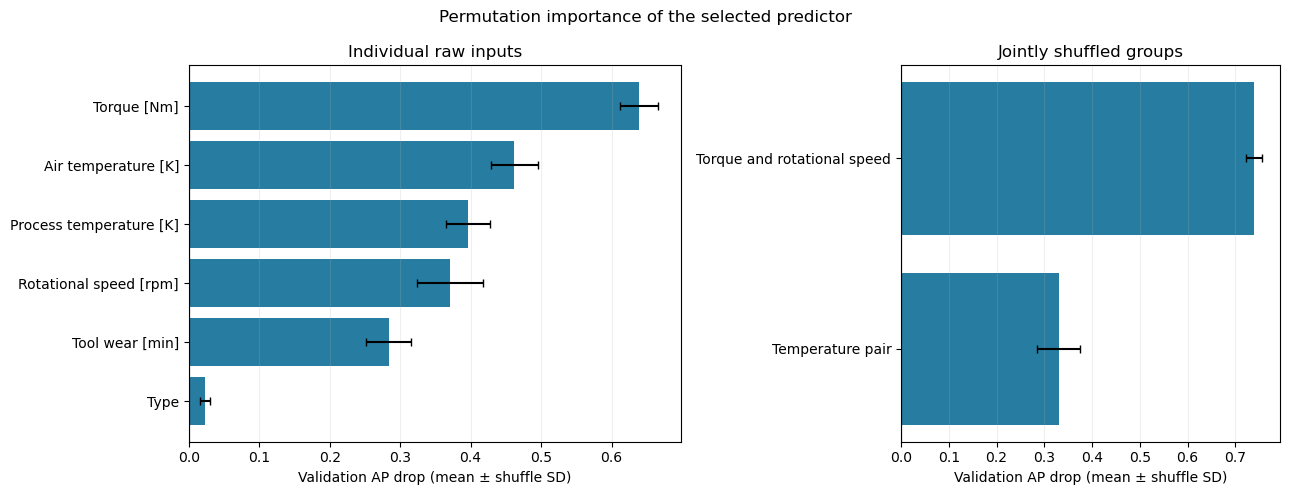

In [3]:
permutation_groups = [
    {"name": column, "kind": "individual", "columns": [column]}
    for column in RAW_COLUMNS
]
permutation_groups += [
    {
        "name": "Temperature pair",
        "kind": "group",
        "columns": ["Air temperature [K]", "Process temperature [K]"],
    },
    {
        "name": "Torque and rotational speed",
        "kind": "group",
        "columns": ["Torque [Nm]", "Rotational speed [rpm]"],
    },
]
shuffle_rng = np.random.default_rng(SEED)
row_permutations = [
    shuffle_rng.permutation(len(X_validation_raw))
    for _ in range(PERMUTATION_REPEATS)
]
permutation_records = []
for group in permutation_groups:
    started = time.perf_counter()
    for repeat, permutation in enumerate(row_permutations, start=1):
        changed = X_validation_raw.copy()
        changed.loc[:, group["columns"]] = (
            X_validation_raw.iloc[permutation][group["columns"]].to_numpy()
        )
        shuffled_ap = average_precision_score(y_validation, predict_raw(changed))
        permutation_records.append({
            "feature_or_group": group["name"],
            "kind": group["kind"],
            "raw_columns": "|".join(group["columns"]),
            "repeat": repeat,
            "reference_AP": baseline_ap,
            "shuffled_AP": shuffled_ap,
            "AP_drop": baseline_ap - shuffled_ap,
        })
    print(f"Completed {group['name']} ({time.perf_counter() - started:.1f}s)")

permutation_runs = pd.DataFrame(permutation_records)
permutation_summary = (
    permutation_runs.groupby(["kind", "feature_or_group"], sort=False)["AP_drop"]
    .agg(mean_AP_drop="mean", std_AP_drop="std", minimum_AP_drop="min", maximum_AP_drop="max")
    .reset_index()
    .sort_values(["kind", "mean_AP_drop"], ascending=[False, False])
    .reset_index(drop=True)
)
display(permutation_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})
for ax, kind, title in zip(
    axes, ["individual", "group"], ["Individual raw inputs", "Jointly shuffled groups"]
):
    subset = permutation_summary.loc[permutation_summary["kind"].eq(kind)].sort_values("mean_AP_drop")
    ax.barh(
        subset["feature_or_group"], subset["mean_AP_drop"],
        xerr=subset["std_AP_drop"], color="#277DA1", capsize=3,
    )
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Validation AP drop (mean ± shuffle SD)")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Permutation importance of the selected predictor")
fig.tight_layout()
fig.savefig(VISUALS / "permutation_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Select observations and the SHAP reference

I choose a simple random sample of 128 validation rows, without balancing the target, for the SHAP global summary. Its failure count may be small, so its ranking is a sample description rather than a precise population estimate.

For individual review, I select one case from each available outcome category: the highest-scoring TP, FP, and FN, and the lowest-scoring TN, with ties resolved by UDI. These are deliberately selected examples and are excluded from the global averages unless they were already in the random sample.

I draw 64 background rows at random from training only. SHAP explains each score relative to the mean model score on this background. That reference is a model output, not the observed failure rate.

In [4]:
case_rules = {
    "TP": ("Highest-scoring correctly flagged failure", False),
    "FP": ("Highest-scoring false alarm", False),
    "FN": ("Highest-scoring missed failure", False),
    "TN": ("Lowest-scoring correctly unflagged observation", True),
}
case_rows = []
for outcome, (rule, ascending) in case_rules.items():
    available = observations.loc[observations["outcome"].eq(outcome)].reset_index()
    if available.empty:
        print(f"No {outcome} case exists at the saved demonstration threshold.")
        continue
    selected_case = available.sort_values(
        ["failure_score", "UDI"], ascending=[ascending, True]
    ).iloc[0]
    case_rows.append({
        "case": outcome,
        "UDI": int(selected_case["UDI"]),
        "selection_rule": rule,
        "actual_failure": int(selected_case[TARGET]),
        "predicted_failure": int(selected_case["predicted_failure"]),
        "failure_score": float(selected_case["failure_score"]),
        "demonstration_threshold": THRESHOLD,
    })
local_cases = pd.DataFrame(case_rows)
global_ids = (
    X_validation_raw.sample(n=min(SHAP_GLOBAL_ROWS, len(X_validation_raw)), random_state=SEED)
    .index.to_numpy()
)
background_ids = (
    X_train_raw.sample(n=min(SHAP_BACKGROUND_ROWS, len(X_train_raw)), random_state=SEED)
    .index.to_numpy()
)
explain_ids = np.array(list(dict.fromkeys([*global_ids, *local_cases["UDI"].tolist()])), dtype=int)
assert set(background_ids).issubset(set(train_ids))
assert set(explain_ids).issubset(set(validation_ids))
assert set(explain_ids).isdisjoint(test_ids)

# Type codes are labels for the SHAP masker only. The predictor receives the original category.
TYPE_TO_CODE = {name: position for position, name in enumerate(schema["valid_Type_values"])}
CODE_TO_TYPE = {position: name for name, position in TYPE_TO_CODE.items()}
TYPE_POSITION = RAW_COLUMNS.index("Type")

def encode_for_shap(raw):
    encoded = raw.loc[:, RAW_COLUMNS].copy()
    encoded["Type"] = encoded["Type"].map(TYPE_TO_CODE)
    if encoded.isna().any().any():
        raise ValueError("SHAP input contains missing values or an unknown Type.")
    return encoded.astype(float)

def decode_from_shap(encoded):
    values = np.asarray(encoded, dtype=float)
    if values.ndim == 1:
        values = values.reshape(1, -1)
    if values.shape[1] != len(RAW_COLUMNS) or not np.isfinite(values).all():
        raise ValueError("The SHAP input shape or values are invalid.")
    type_values = values[:, TYPE_POSITION]
    type_codes = np.rint(type_values).astype(int)
    if not np.allclose(type_values, type_codes, atol=1e-12, rtol=0):
        raise ValueError("Type codes must remain discrete categories.")
    if not np.isin(type_codes, list(CODE_TO_TYPE)).all():
        raise ValueError("The SHAP masker produced an unknown Type code.")
    raw = pd.DataFrame(values, columns=RAW_COLUMNS)
    raw["Type"] = [CODE_TO_TYPE[value] for value in type_codes]
    return raw

def shap_score(encoded):
    return predict_raw(decode_from_shap(encoded))

background_encoded = encode_for_shap(X_train_raw.loc[background_ids])
explain_encoded = encode_for_shap(X_validation_raw.loc[explain_ids])
np.testing.assert_allclose(
    shap_score(explain_encoded), observations.loc[explain_ids, "failure_score"],
    atol=1e-12, rtol=0,
)
background_score = float(predict_raw(X_train_raw.loc[background_ids]).mean())
sample_manifest = pd.concat([
    pd.DataFrame({
        "UDI": background_ids, "role": "training_background",
        "split": "train", "in_global_summary": False,
    }),
    pd.DataFrame({
        "UDI": explain_ids, "role": "validation_explanation",
        "split": "validation", "in_global_summary": np.isin(explain_ids, global_ids),
    }),
], ignore_index=True)
display(local_cases)
print(f"Random global sample: {len(global_ids)} rows, {int(y_validation.loc[global_ids].sum())} failures.")
print(f"Training background: {len(background_ids)} rows; mean model score = {background_score:.6f}")

Random global sample: 128 rows, 8 failures.
Training background: 64 rows; mean model score = 0.037603


,case,UDI,selection_rule,actual_failure,predicted_failure,failure_score,demonstration_threshold
0,TP,4463,Highest-scoring correctly flagged failure,1,1,0.976679,0.346952
1,FP,4192,Highest-scoring false alarm,0,1,0.706342,0.346952
2,FN,5618,Highest-scoring missed failure,1,0,0.271300,0.346952
3,TN,441,Lowest-scoring correctly unflagged observation,0,0,0.000766,0.346952


## 5. Compute SHAP values for the complete predictor

I use model-agnostic Exact SHAP on the six original inputs. With six features there are only 64 masking coalitions. I rebuild both engineered features inside every prediction call, so the contributions include their downstream effects.

The coalition calculation is exact for the chosen finite background and independent masking definition. The background and validation sample still introduce sampling uncertainty. Independently replacing features can break correlations, including the relationship between the temperatures; these are explanations of the fitted model under that masking rule, not physical causes.

SHAP values use failure-score units. Positive values raise the score relative to the background reference; negative values lower it. The Type codes are only discrete masker labels and do not imply an ordinal relationship in the fitted model. [Exact SHAP](https://shap.readthedocs.io/en/latest/generated/shap.ExactExplainer.html), [background masking](https://shap.readthedocs.io/en/latest/generated/shap.maskers.Independent.html)

In [5]:
masker = shap.maskers.Independent(background_encoded, max_samples=len(background_encoded))
explainer = shap.ExactExplainer(
    shap_score, masker, feature_names=RAW_COLUMNS, link=shap.links.identity,
)
value_chunks = []
base_chunks = []
shap_started = time.perf_counter()
for start in range(0, len(explain_encoded), SHAP_CHUNK_SIZE):
    stop = min(start + SHAP_CHUNK_SIZE, len(explain_encoded))
    with threadpool_limits(limits=1):
        result = explainer(
            explain_encoded.iloc[start:stop],
            max_evals=2 ** len(RAW_COLUMNS), batch_size=4096, silent=True,
        )
    value_chunks.append(np.asarray(result.values, dtype=float))
    base_chunks.append(np.asarray(result.base_values, dtype=float).reshape(-1))
    print(f"Explained {stop}/{len(explain_encoded)} validation rows ({time.perf_counter() - shap_started:.1f}s)")

shap_values = np.vstack(value_chunks)
shap_base_values = np.concatenate(base_chunks)
if shap_values.shape != (len(explain_ids), len(RAW_COLUMNS)):
    raise ValueError("The SHAP values do not match the six-input explanation.")
explained_scores = observations.loc[explain_ids, "failure_score"].to_numpy()
reconstructed_scores = shap_base_values + shap_values.sum(axis=1)
additivity_error = np.abs(reconstructed_scores - explained_scores)
np.testing.assert_allclose(reconstructed_scores, explained_scores, atol=1e-8, rtol=0)
np.testing.assert_allclose(shap_base_values, background_score, atol=1e-8, rtol=0)
shap_by_id = pd.DataFrame(shap_values, columns=RAW_COLUMNS, index=explain_ids)
shap_by_id.index.name = "UDI"
base_by_id = pd.Series(shap_base_values, index=explain_ids)
additivity = pd.DataFrame({
    "UDI": explain_ids,
    "base_score": shap_base_values,
    "sum_SHAP": shap_values.sum(axis=1),
    "reconstructed_score": reconstructed_scores,
    "model_score": explained_scores,
    "absolute_error": additivity_error,
})
print(f"Maximum SHAP reconstruction error: {additivity_error.max():.3e}")

Explained 16/131 validation rows (32.5s)
Explained 32/131 validation rows (39.8s)
Explained 48/131 validation rows (47.2s)
Explained 64/131 validation rows (54.6s)
Explained 80/131 validation rows (62.1s)
Explained 96/131 validation rows (69.7s)
Explained 112/131 validation rows (77.2s)
Explained 128/131 validation rows (84.1s)
Explained 131/131 validation rows (85.4s)
Maximum SHAP reconstruction error: 1.332e-15


## 6. Summarize the SHAP contributions

I rank the raw inputs by mean absolute SHAP value within the random validation sample. This measures the size of their score contributions, which differs from the AP loss measured by permutation importance. The rankings need not match.

The effect plots show how each raw value relates to its contribution in these observations. Other inputs and interactions also affect each point, so I do not interpret a pattern as a causal effect or a universal operating rule.

,feature,mean_absolute_SHAP,mean_signed_SHAP,sample_rows
0,Torque [Nm],0.033400,-0.000893,128
1,Air temperature [K],0.033255,0.010799,128
2,Rotational speed [rpm],0.029289,0.016372,128
3,Process temperature [K],0.025366,-0.008028,128
4,Tool wear [min],0.023808,-0.010067,128
5,Type,0.003840,-0.002692,128


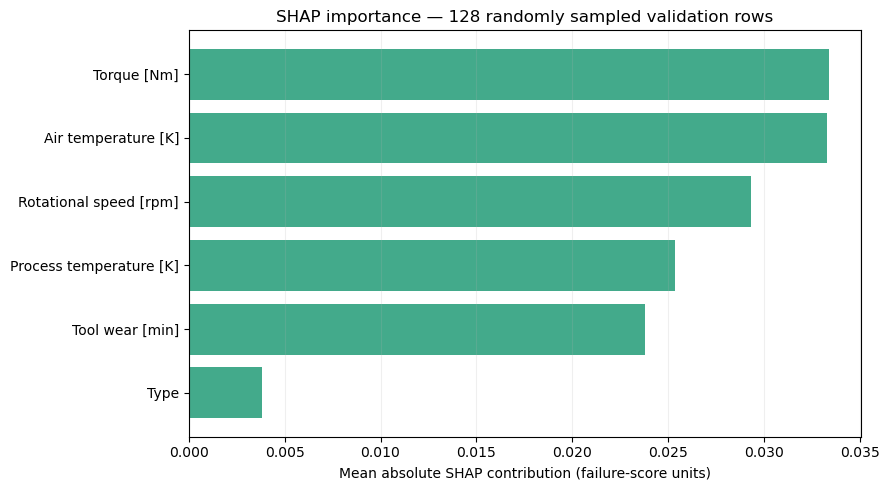

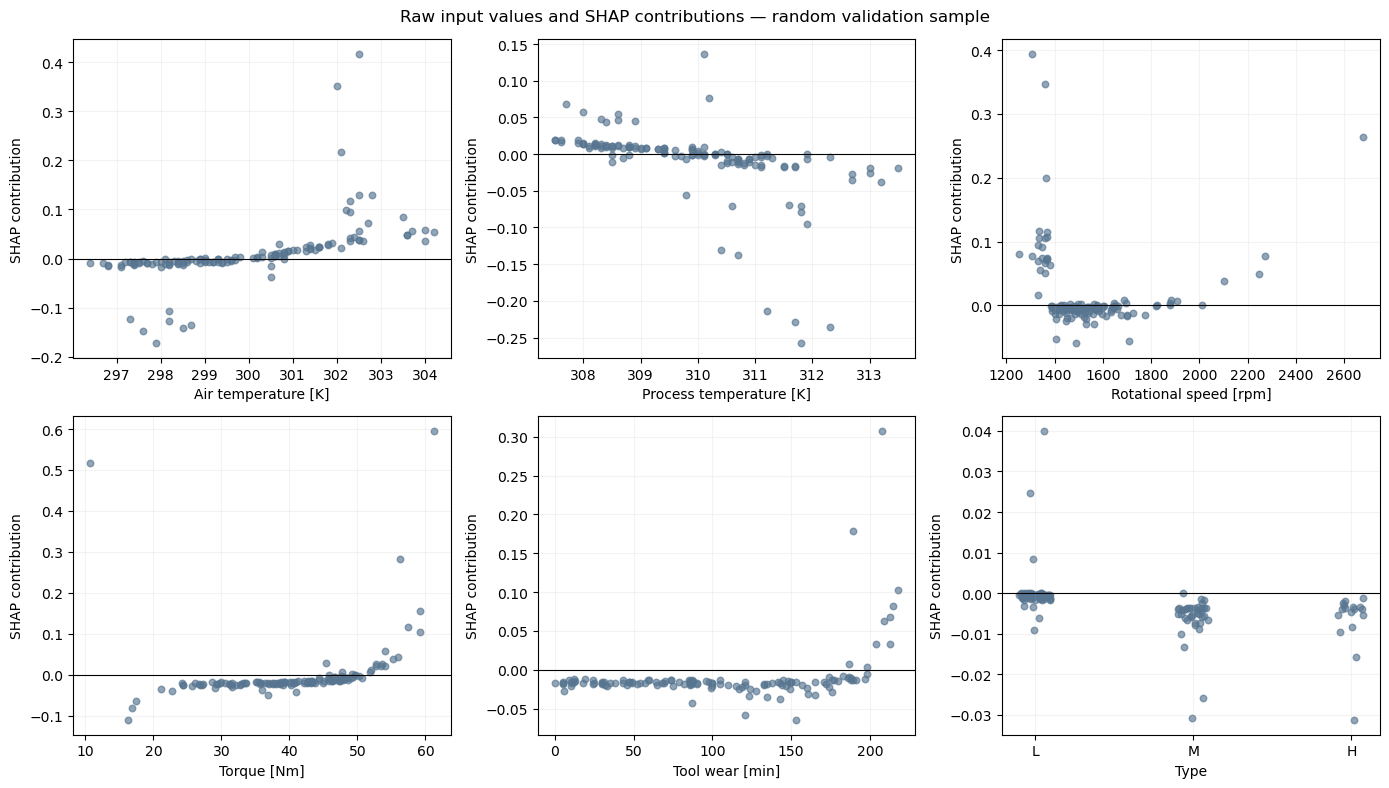

In [6]:
global_shap = shap_by_id.loc[global_ids]
shap_global_summary = pd.DataFrame({
    "feature": RAW_COLUMNS,
    "mean_absolute_SHAP": global_shap.abs().mean().to_numpy(),
    "mean_signed_SHAP": global_shap.mean().to_numpy(),
    "sample_rows": len(global_ids),
}).sort_values("mean_absolute_SHAP", ascending=False).reset_index(drop=True)
display(shap_global_summary)

fig, ax = plt.subplots(figsize=(9, 5))
ordered = shap_global_summary.sort_values("mean_absolute_SHAP")
ax.barh(ordered["feature"], ordered["mean_absolute_SHAP"], color="#43AA8B")
ax.set_xlabel("Mean absolute SHAP contribution (failure-score units)")
ax.set_title(f"SHAP importance — {len(global_ids)} randomly sampled validation rows")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(VISUALS / "shap_global_importance.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
jitter_rng = np.random.default_rng(SEED)
for ax, column in zip(axes.flat, RAW_COLUMNS):
    raw_values = X_validation_raw.loc[global_ids, column]
    effects = global_shap[column]
    if column == "Type":
        categories = schema["valid_Type_values"]
        positions = raw_values.map({value: i for i, value in enumerate(categories)}).to_numpy()
        ax.scatter(positions + jitter_rng.uniform(-0.1, 0.1, len(positions)), effects, s=22, alpha=0.65, color="#577590")
        ax.set_xticks(range(len(categories)), labels=categories)
    else:
        ax.scatter(raw_values, effects, s=22, alpha=0.65, color="#577590")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(column)
    ax.set_ylabel("SHAP contribution")
    ax.grid(alpha=0.15)
fig.suptitle("Raw input values and SHAP contributions — random validation sample")
fig.tight_layout()
fig.savefig(VISUALS / "shap_feature_effects.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Explain correct predictions and errors

I inspect the four selected examples with waterfall plots. Each plot starts at the training-background mean score, then adds the six feature contributions to reconstruct the model score. The saved demonstration threshold converts that score into a predicted label; it is not part of the SHAP calculation.

A missed failure can have a low score even when its label is correct. The explanation describes the model's response to the available measurements; it does not establish the root cause of that failure. I keep these selected error examples separate from general performance claims.

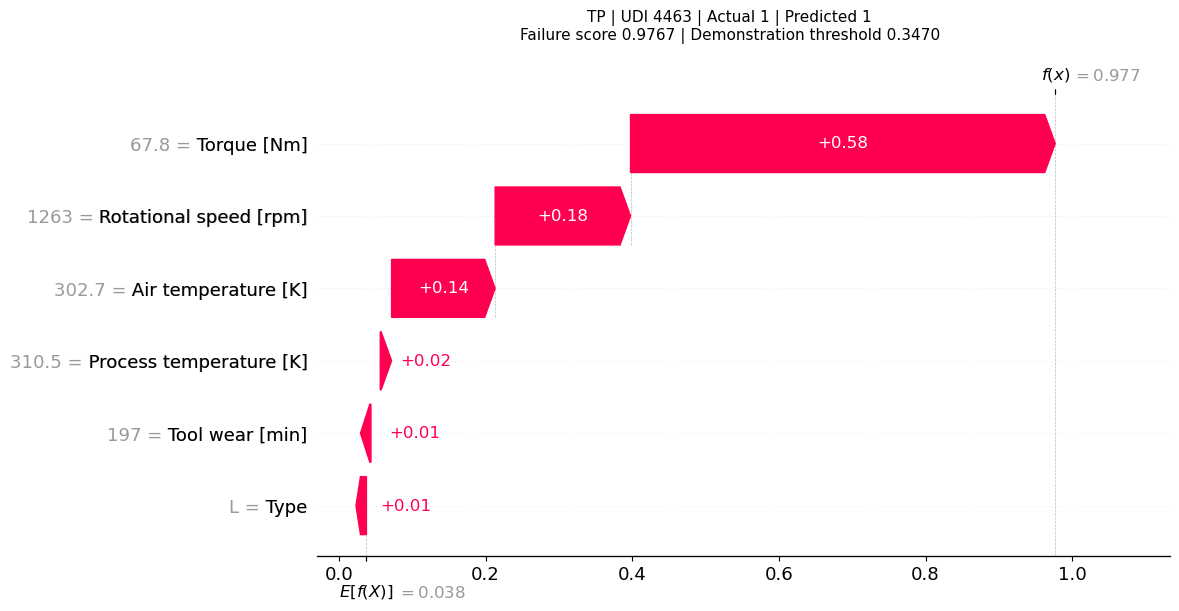

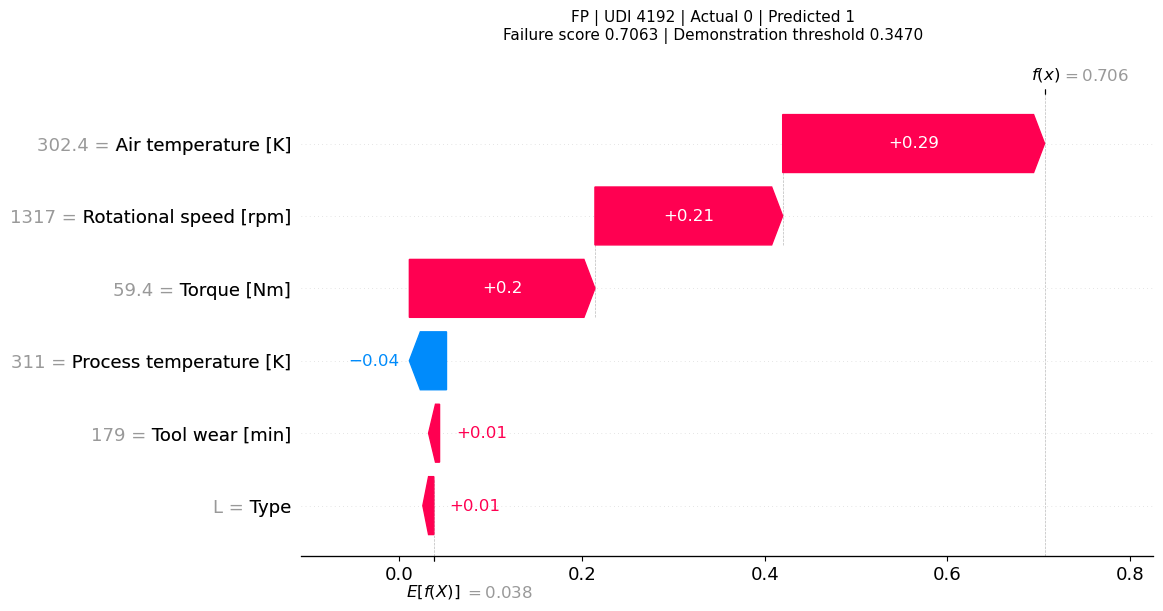

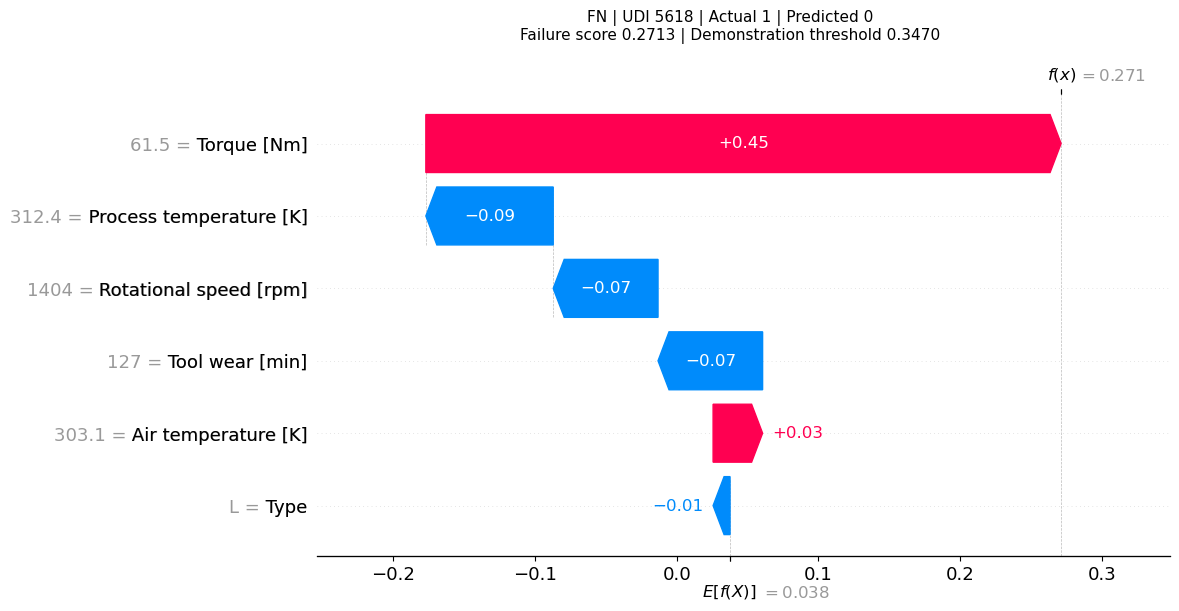

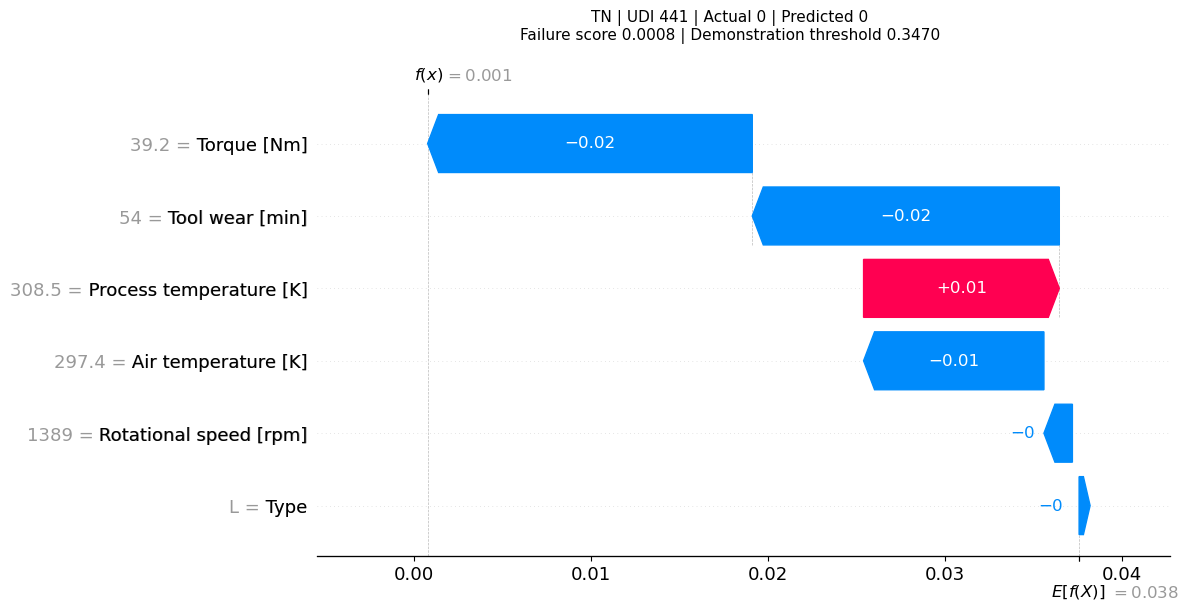

,case,UDI,feature,raw_value,SHAP_contribution,direction,base_score,failure_score,demonstration_threshold
15,FN,5618,Torque [Nm],61.5,0.448441,raises score,0.037603,0.271300,0.346952
12,FN,5618,Air temperature [K],303.1,0.034947,raises score,0.037603,0.271300,0.346952
17,FN,5618,Type,L,-0.011966,lowers score,0.037603,0.271300,0.346952
16,FN,5618,Tool wear [min],127,-0.073822,lowers score,0.037603,0.271300,0.346952
14,FN,5618,Rotational speed [rpm],1404,-0.073985,lowers score,0.037603,0.271300,0.346952
13,FN,5618,Process temperature [K],312.4,-0.089917,lowers score,0.037603,0.271300,0.346952
6,FP,4192,Air temperature [K],302.4,0.286782,raises score,0.037603,0.706342,0.346952
8,FP,4192,Rotational speed [rpm],1317,0.205564,raises score,0.037603,0.706342,0.346952
9,FP,4192,Torque [Nm],59.4,0.203206,raises score,0.037603,0.706342,0.346952
10,FP,4192,Tool wear [min],179,0.007592,raises score,0.037603,0.706342,0.346952


In [7]:
local_records = []
for case in local_cases.itertuples(index=False):
    udi = int(case.UDI)
    raw_row = X_validation_raw.loc[udi]
    contributions = shap_by_id.loc[udi]
    for feature in RAW_COLUMNS:
        local_records.append({
            "case": case.case, "UDI": udi, "feature": feature,
            "raw_value": raw_row[feature],
            "SHAP_contribution": float(contributions[feature]),
            "direction": "raises score" if contributions[feature] > 0 else (
                "lowers score" if contributions[feature] < 0 else "no contribution"
            ),
            "base_score": float(base_by_id.loc[udi]),
            "failure_score": case.failure_score,
            "demonstration_threshold": THRESHOLD,
        })
    local_explanation = shap.Explanation(
        values=contributions.to_numpy(),
        base_values=float(base_by_id.loc[udi]),
        data=raw_row.to_numpy(dtype=object),
        feature_names=RAW_COLUMNS,
    )
    shap.plots.waterfall(local_explanation, max_display=len(RAW_COLUMNS), show=False)
    fig = plt.gcf()
    fig.set_size_inches(11, 6)
    fig.suptitle(
        f"{case.case} | UDI {udi} | Actual {case.actual_failure} | Predicted {case.predicted_failure}\n"
        f"Failure score {case.failure_score:.4f} | Demonstration threshold {THRESHOLD:.4f}",
        y=1.02, fontsize=11,
    )
    fig.savefig(VISUALS / f"shap_waterfall_{case.case.lower()}_UDI_{udi}.png", dpi=160, bbox_inches="tight")
    plt.show()
local_contributions = pd.DataFrame(local_records)
display(local_contributions.sort_values(["case", "SHAP_contribution"], ascending=[True, False]))

## 8. Inspect the voting components

For an uncalibrated soft voting model, the ensemble score is the weighted average of the component scores. I show those scores for the selected cases and verify the arithmetic.

The weighted score terms explain how the ensemble combines its members. They are not feature attributions. Component scores are also not automatically calibrated failure probabilities.

In [8]:
member_records = []
is_uncalibrated_soft_vote = (
    metadata["score_representation"] == "uncalibrated"
    and getattr(predictor, "voting", None) == "soft"
    and hasattr(predictor, "estimators_")
)
if is_uncalibrated_soft_vote:
    active_names = [name for name, estimator in predictor.estimators if estimator != "drop"]
    if predictor.weights is None:
        member_weights = np.ones(len(predictor.estimators_), dtype=float)
    else:
        member_weights = np.asarray([
            weight for (_, estimator), weight in zip(predictor.estimators, predictor.weights)
            if estimator != "drop"
        ], dtype=float)
    normalized_weights = member_weights / member_weights.sum()
    local_ids = local_cases["UDI"].to_numpy()
    local_inputs = prepare_features(X_validation_raw.loc[local_ids])
    with threadpool_limits(limits=1):
        component_scores = np.column_stack([
            member.predict_proba(local_inputs)[:, POSITIVE_POSITION]
            for member in predictor.estimators_
        ])
    weighted_terms = component_scores * normalized_weights
    np.testing.assert_allclose(
        weighted_terms.sum(axis=1),
        observations.loc[local_ids, "failure_score"],
        atol=1e-12, rtol=0,
    )
    for row_index, case in enumerate(local_cases.itertuples(index=False)):
        for member_index, name in enumerate(active_names):
            member_records.append({
                "case": case.case, "UDI": int(case.UDI), "member": name,
                "member_score": float(component_scores[row_index, member_index]),
                "normalized_weight": float(normalized_weights[member_index]),
                "weighted_score_term": float(weighted_terms[row_index, member_index]),
                "ensemble_score": float(case.failure_score),
            })
    member_scores = pd.DataFrame(member_records)
    display(member_scores)
    print("The weighted component terms reproduce the selected ensemble scores.")
else:
    member_scores = pd.DataFrame(columns=[
        "case", "UDI", "member", "member_score", "normalized_weight",
        "weighted_score_term", "ensemble_score",
    ])
    print("Component arithmetic is only shown when the selected artifact is an uncalibrated soft voting model.")

The weighted component terms reproduce the selected ensemble scores.


,case,UDI,member,member_score,normalized_weight,weighted_score_term,ensemble_score
0,TP,4463,rf,9.426667e-01,0.4,3.770667e-01,0.976679
1,TP,4463,gb,9.990383e-01,0.4,3.996153e-01,0.976679
2,TP,4463,mlp,9.999856e-01,0.2,1.999971e-01,0.976679
3,FP,4192,rf,5.371931e-01,0.4,2.148772e-01,0.706342
4,FP,4192,gb,9.458589e-01,0.4,3.783436e-01,0.706342
5,FP,4192,mlp,5.656065e-01,0.2,1.131213e-01,0.706342
6,FN,5618,rf,3.923492e-01,0.4,1.569397e-01,0.271300
7,FN,5618,gb,2.722904e-01,0.4,1.089161e-01,0.271300
8,FN,5618,mlp,2.722271e-02,0.2,5.444541e-03,0.271300
9,TN,441,rf,0.000000e+00,0.4,0.000000e+00,0.000766


## 9. Findings and interpretation

I generate the summary below from the computed results. A high importance value shows how this predictor uses an input under the chosen explanation method. It does not justify changing a machine setting or removing a feature without a separate evaluation.

In [9]:
top_permutation = (
    permutation_summary.loc[permutation_summary["kind"].eq("individual")]
    .sort_values("mean_AP_drop", ascending=False).iloc[0]
)
top_shap = shap_global_summary.iloc[0]
summary_lines = [
    f"- I reproduced the selected **{metadata['candidate']}** model's validation scores (AP **{baseline_ap:.4f}**).",
    f"- **{top_permutation['feature_or_group']}** has the largest individual mean permutation AP drop "
    f"(**{top_permutation['mean_AP_drop']:.4f}**, shuffle SD **{top_permutation['std_AP_drop']:.4f}**).",
    f"- **{top_shap['feature']}** has the largest mean absolute SHAP contribution in the "
    f"**{len(global_ids)}** randomly sampled validation rows (**{top_shap['mean_absolute_SHAP']:.4f}** score units).",
    f"- The global SHAP sample contains **{int(y_validation.loc[global_ids].sum())}** failure observations; "
    "I treat its ranking as descriptive.",
    f"- The largest SHAP score-reconstruction error is **{additivity_error.max():.2e}**.",
]
for case in local_cases.itertuples(index=False):
    impacts = shap_by_id.loc[int(case.UDI)]
    strongest = impacts.abs().idxmax()
    summary_lines.append(
        f"- For the selected **{case.case}** example (UDI **{int(case.UDI)}**), "
        f"**{strongest}** has the largest absolute contribution "
        f"(**{impacts[strongest]:+.4f}**); the model score is **{case.failure_score:.4f}**."
    )
summary_lines += [
    "- I used training rows for the SHAP background and validation rows for explanations. "
    "The final test set remains unscored, although it was included in early exploratory analysis.",
    "- These validation observations have already supported model, calibration, and demonstration-threshold choices. "
    "The explanations are exploratory and do not add an independent performance evaluation.",
    "- The demonstration threshold remains provisional because operating costs and a required recall target have not been specified.",
]
findings_markdown = "\n".join(summary_lines)
display(Markdown(findings_markdown))

- I reproduced the selected **weighted_voting** model's validation scores (AP **0.8419**).
- **Torque [Nm]** has the largest individual mean permutation AP drop (**0.6390**, shuffle SD **0.0267**).
- **Torque [Nm]** has the largest mean absolute SHAP contribution in the **128** randomly sampled validation rows (**0.0334** score units).
- The global SHAP sample contains **8** failure observations; I treat its ranking as descriptive.
- The largest SHAP score-reconstruction error is **1.33e-15**.
- For the selected **TP** example (UDI **4463**), **Torque [Nm]** has the largest absolute contribution (**+0.5790**); the model score is **0.9767**.
- For the selected **FP** example (UDI **4192**), **Air temperature [K]** has the largest absolute contribution (**+0.2868**); the model score is **0.7063**.
- For the selected **FN** example (UDI **5618**), **Torque [Nm]** has the largest absolute contribution (**+0.4484**); the model score is **0.2713**.
- For the selected **TN** example (UDI **441**), **Torque [Nm]** has the largest absolute contribution (**-0.0184**); the model score is **0.0008**.
- I used training rows for the SHAP background and validation rows for explanations. The final test set remains unscored, although it was included in early exploratory analysis.
- These validation observations have already supported model, calibration, and demonstration-threshold choices. The explanations are exploratory and do not add an independent performance evaluation.
- The demonstration threshold remains provisional because operating costs and a required recall target have not been specified.

## 10. Save the explanation outputs

I save the numeric results, selected observation IDs, settings, and figures so I can review each explanation later. I leave the fitted model and existing experiment files unchanged.

My next step is to agree on an operating policy, freeze the prediction procedure, and evaluate it on the reserved final test set with the earlier EDA exposure documented.

In [10]:
permutation_runs.to_csv(REPORTS / "permutation_runs.csv", index=False)
permutation_summary.to_csv(REPORTS / "permutation_importance.csv", index=False)
sample_manifest.to_csv(REPORTS / "explanation_sample_manifest.csv", index=False)
local_cases.to_csv(REPORTS / "local_cases.csv", index=False)
shap_global_summary.to_csv(REPORTS / "shap_global_importance.csv", index=False)
shap_by_id.to_csv(REPORTS / "shap_values.csv")
additivity.to_csv(REPORTS / "shap_additivity_check.csv", index=False)
local_contributions.to_csv(REPORTS / "local_shap_contributions.csv", index=False)
member_scores.to_csv(REPORTS / "voting_member_scores.csv", index=False)

explained_observations = observations.loc[explain_ids].copy()
explained_observations["in_global_summary"] = np.isin(explain_ids, global_ids)
explained_observations["SHAP_base_score"] = shap_base_values
explained_observations.to_csv(REPORTS / "explained_observations.csv")
(REPORTS / "findings.md").write_text(findings_markdown + "\n", encoding="utf-8")

settings = {
    "candidate": metadata["candidate"],
    "score_representation": metadata["score_representation"],
    "feature_set": schema["feature_set"],
    "raw_explanation_columns": RAW_COLUMNS,
    "model_input_columns": MODEL_COLUMNS,
    "derived_features_recomputed_on_every_prediction": True,
    "model_refitted": False,
    "demonstration_threshold": THRESHOLD,
    "threshold_changed": False,
    "seed": SEED,
    "permutation_scoring": "average_precision",
    "permutation_repeats": PERMUTATION_REPEATS,
    "permutation_groups": permutation_groups,
    "shuffle_SD_is_confidence_interval": False,
    "SHAP_method": "ExactExplainer",
    "SHAP_masker": "Independent",
    "SHAP_link": "identity",
    "SHAP_units": "failure score",
    "SHAP_coalition_count": 2 ** len(RAW_COLUMNS),
    "SHAP_background_sampling": "simple random sample from training",
    "SHAP_background_rows": len(background_ids),
    "SHAP_background_mean_model_score": background_score,
    "SHAP_global_sampling": "simple random sample from validation; no target balancing",
    "SHAP_global_rows": len(global_ids),
    "SHAP_global_failures": int(y_validation.loc[global_ids].sum()),
    "SHAP_explained_rows_including_local_cases": len(explain_ids),
    "SHAP_max_additivity_error": float(additivity_error.max()),
    "Type_masker_codes": TYPE_TO_CODE,
    "Type_codes_passed_to_fitted_predictor": False,
    "final_test_scored": False,
    "early_EDA_included_final_test_rows": metadata["early_EDA_included_final_test_rows"],
    "validation_reused_for_model_and_policy_exploration": True,
    "causal_interpretation": False,
    "input_checksums": input_checksums,
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
        "SHAP": shap.__version__, "joblib": joblib.__version__,
    },
}
(REPORTS / "explanation_settings.json").write_text(
    json.dumps(settings, indent=2), encoding="utf-8"
)

for name, path in INPUTS.items():
    if sha256(path) != input_checksums[name]:
        raise AssertionError(f"An existing input file was changed: {name}")
assert set(explain_ids).isdisjoint(test_ids)
assert set(background_ids).issubset(set(train_ids))
np.testing.assert_allclose(
    predict_raw(X_validation_raw), validation_scores, atol=1e-12, rtol=0
)
print("Saved reports:", REPORTS.relative_to(PROJECT_ROOT))
print("Saved figures:", VISUALS.relative_to(PROJECT_ROOT))
print("Verified: original inputs unchanged, predictions reproduced, SHAP sums checked.")
print("The fitted model and demonstration threshold are unchanged. Final test remains unscored.")

Saved reports: reports\model_explainability
Saved figures: visuals\model_explainability
Verified: original inputs unchanged, predictions reproduced, SHAP sums checked.
The fitted model and demonstration threshold are unchanged. Final test remains unscored.
